**Doel** Mijn daatset beschrijft alleen de klant zelf. In dit notebook voeg ik informatie over de omgeving van de klant toe. Het mediaan huishoudinkomen van de postcode waar de klant woont. Ik onderzoek of klanten in buurten met een lager inkomen vaker vertrekken.

**Bronnen**
1. Originele dataset: IBM, Telco Customer Churn, via Kaggle (BlastChar). 7.043 fictieve klanten. 
   
2. Koppelbestand: IBM, Telco Customer Churn (IBM-versie), via Kaggle (yeanzc). Dezelfde klanten, met postcode en vertrekreden.

3.  Extra databron: U.S. Census Bureau, American Community Survey 5-Year Estimates 2023, tabel B19013 (Median Household Income), per postcodegebied in Californië, via data.census.gov.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
klanten = pd.read_csv("../Sprint 1/WA_Fn-UseC_-Telco-Customer-Churn.csv")
klanten.shape

(7043, 21)

In [4]:
ibm = pd.read_excel("Telco_customer_churn.xlsx")
ibm.shape

(7043, 33)

In [5]:
ibm[["CustomerID", "City", "Zip Code", "Churn Label", "Churn Reason"]].head()

,CustomerID,City,Zip Code,Churn Label,Churn Reason
0,3668-QPYBK,Los Angeles,90003,Yes,Competitor made better offer
1,9237-HQITU,Los Angeles,90005,Yes,Moved
2,9305-CDSKC,Los Angeles,90006,Yes,Moved
3,7892-POOKP,Los Angeles,90010,Yes,Moved
4,0280-XJGEX,Los Angeles,90015,Yes,Competitor had better devices


In [6]:
inkomen = pd.read_csv("ACSDT5Y2023.B19013-Data.csv")
inkomen.head()

,GEO_ID,NAME,B19013_001E,B19013_001M,Unnamed: 4
0,Geography,Geographic Area Name,Estimate!!Median household income in the past ...,Margin of Error!!Median household income in th...,NaN
1,860Z200US89010,ZCTA5 89010,58125,32830,NaN
2,860Z200US89019,ZCTA5 89019,50106,25129,NaN
3,860Z200US89060,ZCTA5 89060,49008,8698,NaN
4,860Z200US89061,ZCTA5 89061,69609,10478,NaN


### Wat ik heb gezien
- De orginele datset en de IBM-versie bevatten allebei 7.043 klanten. De IBM-versie heeft extra kolommen, waaronder de postcode en de vertrek reden (Churn reason).
- Het inkomensbestand bevar per postcode gebied het mediaan huishoudinkomen. De eerste rij bevat uitleg van de kolommen inplaats van data. en de postcode staat in een tekst, dit moet ik eerst opschonen.

### Stap 2: Het inkomensbestand opschonen
Voordat ik het inkomen aan de klanten kan koppelen, moet het bestand netjes zijn. Alleen data, een postcode als getal en een inkomen als getal.

In [7]:
inkomen = pd.read_csv("ACSDT5Y2023.B19013-Data.csv", skiprows=[1])
inkomen.head()

,GEO_ID,NAME,B19013_001E,B19013_001M,Unnamed: 4
0,860Z200US89010,ZCTA5 89010,58125,32830,NaN
1,860Z200US89019,ZCTA5 89019,50106,25129,NaN
2,860Z200US89060,ZCTA5 89060,49008,8698,NaN
3,860Z200US89061,ZCTA5 89061,69609,10478,NaN
4,860Z200US89439,ZCTA5 89439,98068,31611,NaN


In [8]:
inkomen = inkomen[["NAME", "B19013_001E"]]
inkomen = inkomen.rename(columns={"NAME": "postcode", "B19013_001E": "inkomen"})
inkomen.head()

,postcode,inkomen
0,ZCTA5 89010,58125
1,ZCTA5 89019,50106
2,ZCTA5 89060,49008
3,ZCTA5 89061,69609
4,ZCTA5 89439,98068


In [9]:
inkomen["postcode"] = inkomen["postcode"].str.replace("ZCTA5 ", "").astype(int)
inkomen.head()

,postcode,inkomen
0,89010,58125
1,89019,50106
2,89060,49008
3,89061,69609
4,89439,98068


In [10]:
inkomen[~inkomen["inkomen"].str.isnumeric()]["inkomen"].value_counts()

inkomen
-           210
250,000+     12
Name: count, dtype: int64

In [11]:
inkomen["inkomen"] = inkomen["inkomen"].replace("250,000+", "250000")
inkomen["inkomen"] = pd.to_numeric(inkomen["inkomen"], errors="coerce")
print("Postcodes zonder inkomen:", inkomen["inkomen"].isna().sum())

Postcodes zonder inkomen: 210


In [12]:
print("Aantal postcodes:", len(inkomen))
print("Dubbele postcodes:", inkomen["postcode"].duplicated().sum())
inkomen.describe()

Aantal postcodes: 1808
Dubbele postcodes: 0


,postcode,inkomen
count,1808.000000,1598.000000
mean,93647.268805,98220.051940
std,1824.907631,42770.621134
min,89010.000000,17663.000000
25%,92252.750000,67619.250000
50%,93650.500000,89783.000000
75%,95377.500000,119126.250000
max,97635.000000,250000.000000


### Conclusie stap 2

**Doel:** het inkomensbestand klaarmaken om te koppelen aan de klanten.

**Wat ik heb gedaan:**
- De tweede rij overgeslagen, omdat die uitleg bevatte in plaats van data.
- Alleen de kolommen met de postcode en het inkomen gehouden en ze duidelijke namen gegeven.
- De postcode omgezet van tekst ("ZCTA5 89010") naar een getal (89010), zodat hij overeenkomt met de postcode in de IBM-versie.
- Bij 12 postcodes stond "250,000+". Dat heb ik vervangen door 250.000 dollar, omdat ik alleen weet dat het inkomen minstens zo hoog is.
- Bij 210 postcodes stond "-", omdat de overheid daar geen betrouwbaar cijfer heeft. Deze heb ik leeg gelaten en niet op 0 gezet, omdat het inkomen onbekend is en niet 0.

**Uitkomst:** het bestand bevat 1.808 postcodes in Californië, zonder dubbele postcodes. Bij 1.598 postcodes is het inkomen bekend. Het mediaan huishoudinkomen ligt tussen 17.663 en 250.000 dollar.

### Stap 3: Bestanden koppelen
Ik koppel de bestanden in twee rondes. Eerst haal ik via het klantnummer de postcode en de vetrekreden uit de IBM-versie. Daarna koppel ik via de postcode het inkomen.

In [13]:
ibm_kort = ibm[["CustomerID", "City", "Zip Code", "Churn Label", "Churn Reason"]]
ibm_kort = ibm_kort.rename(columns={"CustomerID": "customerID",
                                    "City": "stad",
                                    "Zip Code": "postcode",
                                    "Churn Label": "churn_ibm",
                                    "Churn Reason": "vertrekreden"})
ibm_kort.head()

,customerID,stad,postcode,churn_ibm,vertrekreden
0,3668-QPYBK,Los Angeles,90003,Yes,Competitor made better offer
1,9237-HQITU,Los Angeles,90005,Yes,Moved
2,9305-CDSKC,Los Angeles,90006,Yes,Moved
3,7892-POOKP,Los Angeles,90010,Yes,Moved
4,0280-XJGEX,Los Angeles,90015,Yes,Competitor had better devices


In [14]:
gekoppeld = klanten.merge(ibm_kort, on="customerID", how="left", validate="one_to_one")
print("Aantal rijen:", len(gekoppeld))
print("Klanten zonder postcode:", gekoppeld["postcode"].isna().sum())


Aantal rijen: 7043
Klanten zonder postcode: 0


In [15]:
print("Churn hetzelfde in beide bestanden:", (gekoppeld["Churn"] == gekoppeld["churn_ibm"]).sum())
gekoppeld = gekoppeld.drop(columns="churn_ibm")

Churn hetzelfde in beide bestanden: 7043


In [16]:
gekoppeld = gekoppeld.merge(inkomen, on="postcode", how="left", validate="many_to_one")
print("Aantal rijen:", len(gekoppeld))
print("Klanten zonder inkomen:", gekoppeld["inkomen"].isna().sum())

Aantal rijen: 7043
Klanten zonder inkomen: 475


In [17]:
gekoppeld[["customerID", "stad", "postcode", "inkomen", "Churn", "vertrekreden"]].head()

,customerID,stad,postcode,inkomen,Churn,vertrekreden
0,7590-VHVEG,Los Angeles,90001,60751.0,No,NaN
1,5575-GNVDE,Los Angeles,90002,56158.0,No,NaN
2,3668-QPYBK,Los Angeles,90003,54781.0,Yes,Competitor made better offer
3,7795-CFOCW,Los Angeles,90004,62655.0,No,NaN
4,9237-HQITU,Los Angeles,90005,52755.0,Yes,Moved


### Conclusie stap 3

**Doel:** de drie bestanden koppelen, zodat bij elke klant het inkomen van zijn buurt en zijn vertrekreden staan.

**Wat ik heb gedaan:**
- Ronde 1: mijn originele dataset gekoppeld aan de IBM-versie via het klantnummer (customerID). Alle 7.043 klanten zijn gekoppeld. Ter controle heb ik gekeken of churn in beide bestanden gelijk is: dat is bij alle 7.043 klanten zo. Het zijn dus echt dezelfde klanten.
- Ronde 2: het resultaat gekoppeld aan het inkomensbestand via de postcode.
- Bij beide koppelingen heb ik gecontroleerd dat er geen klanten zijn verdubbeld of kwijtgeraakt.

**Uitkomst:** 6.568 van de 7.043 klanten (93,3%) hebben een inkomen. Bij 475 klanten ontbreekt het inkomen: 471 wonen in een postcode waarvoor de overheid geen betrouwbaar cijfer heeft, en 4 wonen in postcode 95250 (Sheep Ranch), die niet in het overheidsbestand staat. Deze klanten tellen niet mee in de analyse van het inkomen.

## Stap 4: analyse
### Deel A: hangt het inkomen van de buurt samen met churn?
Mijn verwachting was dat klanten in buurten met een lager inkomen vaker vertrekken, vooral als ze hoge maandkosten hebben. In dit deel toets ik die verwachting.

In [18]:
churn_num = (gekoppeld["Churn"] == "Yes").astype(int)
gekoppeld["churn_num"] = churn_num

met_inkomen = gekoppeld.dropna(subset=["inkomen"]).copy()
gemiddelde = met_inkomen["churn_num"].mean() * 100
print("Klanten met inkomen:", len(met_inkomen))
print("Gemiddelde churn in deze groep:", round(gemiddelde, 1), "%")

Klanten met inkomen: 6568
Gemiddelde churn in deze groep: 26.7 %


In [19]:
met_inkomen["inkomen_groep"] = pd.qcut(met_inkomen["inkomen"], 4,
                                       labels=["laag", "midden-laag", "midden-hoog", "hoog"])

tabel = met_inkomen.groupby("inkomen_groep", observed=True).agg(
    churn_pct=("churn_num", "mean"),
    aantal_klanten=("churn_num", "count"),
    inkomen_van=("inkomen", "min"),
    inkomen_tot=("inkomen", "max"))
tabel["churn_pct"] = (tabel["churn_pct"] * 100).round(1)
tabel

,churn_pct,aantal_klanten,inkomen_van,inkomen_tot
inkomen_groep,,,,
laag,27.5,1645,17663.0,67643.0
midden-laag,26.7,1642,67829.0,89583.0
midden-hoog,26.8,1642,89649.0,118118.0
hoog,25.8,1639,118125.0,250000.0


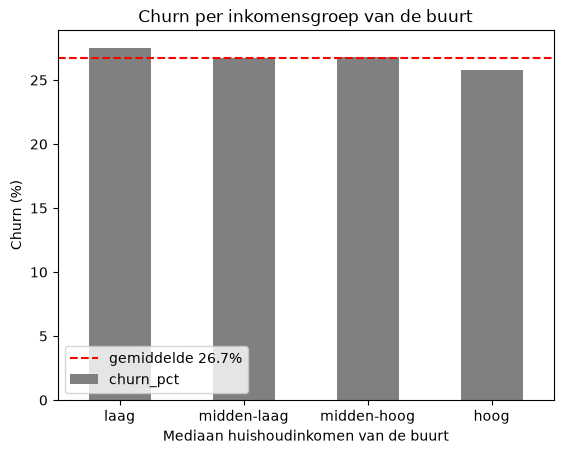

In [20]:
pct = tabel["churn_pct"]
pct.plot(kind="bar", color="grey")
plt.axhline(gemiddelde, color="red", linestyle="--", label=f"gemiddelde {gemiddelde:.1f}%")
plt.title("Churn per inkomensgroep van de buurt")
plt.xlabel("Mediaan huishoudinkomen van de buurt")
plt.ylabel("Churn (%)")
plt.xticks(rotation=0)
plt.legend()
plt.show()

In [21]:
met_inkomen.groupby("Churn")["inkomen"].median()

Churn
No     89861.0
Yes    88173.0
Name: inkomen, dtype: float64

In [22]:
met_inkomen["hoge_kosten"] = met_inkomen["MonthlyCharges"] > 70
pd.crosstab(met_inkomen["inkomen_groep"], met_inkomen["hoge_kosten"],
            values=met_inkomen["churn_num"], aggfunc="mean").mul(100).round(1)

hoge_kosten,False,True
inkomen_groep,,
laag,16.2,38.2
midden-laag,20.2,32.8
midden-hoog,18.4,34.8
hoog,15.5,36.1


### Deel B: vertrekredenen
Via de IBM-versie weet ik voor elke vertrokken klant waarom hij is vertrokken. In dit deel onderzoek ik welke redenen het meest voorkomen.

In [23]:
gekoppeld["vertrekreden"].value_counts()

vertrekreden
Attitude of support person                   192
Competitor offered higher download speeds    189
Competitor offered more data                 162
Don't know                                   154
Competitor made better offer                 140
Attitude of service provider                 135
Competitor had better devices                130
Network reliability                          103
Product dissatisfaction                      102
Price too high                                98
Service dissatisfaction                       89
Lack of self-service on Website               88
Extra data charges                            57
Moved                                         53
Limited range of services                     44
Lack of affordable download/upload speed      44
Long distance charges                         44
Poor expertise of phone support               20
Poor expertise of online support              19
Deceased                                       6
Name: c

In [24]:
categorieen = {
    "Competitor offered higher download speeds": "Concurrent",
    "Competitor offered more data": "Concurrent",
    "Competitor made better offer": "Concurrent",
    "Competitor had better devices": "Concurrent",
    "Attitude of support person": "Service en houding",
    "Attitude of service provider": "Service en houding",
    "Service dissatisfaction": "Service en houding",
    "Poor expertise of phone support": "Service en houding",
    "Poor expertise of online support": "Service en houding",
    "Lack of self-service on Website": "Service en houding",
    "Price too high": "Prijs",
    "Extra data charges": "Prijs",
    "Long distance charges": "Prijs",
    "Lack of affordable download/upload speed": "Prijs",
    "Network reliability": "Product en netwerk",
    "Product dissatisfaction": "Product en netwerk",
    "Limited range of services": "Product en netwerk",
    "Moved": "Overig",
    "Deceased": "Overig",
    "Don't know": "Overig"}

gekoppeld["reden_categorie"] = gekoppeld["vertrekreden"].map(categorieen)
(gekoppeld["reden_categorie"].value_counts(normalize=True) * 100).round(1)

reden_categorie
Concurrent            33.2
Service en houding    29.1
Product en netwerk    13.3
Prijs                 13.0
Overig                11.4
Name: proportion, dtype: float64

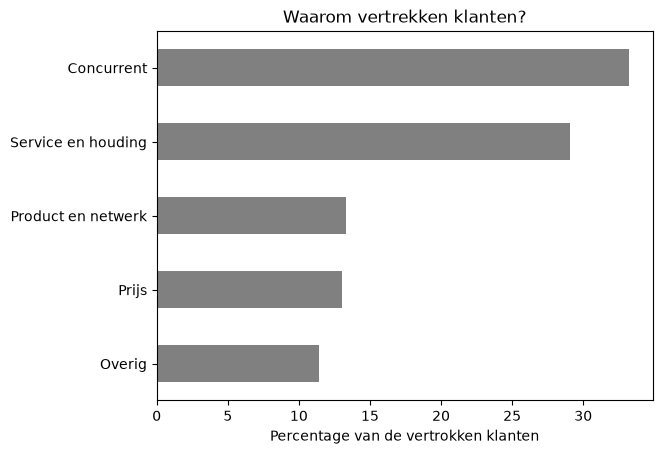

In [25]:
(gekoppeld["reden_categorie"].value_counts(normalize=True) * 100).sort_values().plot(kind="barh", color="grey")
plt.title("Waarom vertrekken klanten?")
plt.xlabel("Percentage van de vertrokken klanten")
plt.ylabel("")
plt.show()

In [26]:
vertrokken = met_inkomen[met_inkomen["Churn"] == "Yes"].copy()
vertrokken["reden_categorie"] = vertrokken["vertrekreden"].map(categorieen)
pd.crosstab(vertrokken["inkomen_groep"], vertrokken["reden_categorie"],
            normalize="index").mul(100).round(1)["Prijs"]

inkomen_groep
laag           10.2
midden-laag    16.7
midden-hoog    12.3
hoog           13.0
Name: Prijs, dtype: float64

### Conclusie stap 4

**Deel A: inkomen van de buurt en churn**
Mijn verwachting was dat klanten in buurten met een lager inkomen vaker vertrekken, vooral bij hoge maandkosten. Die verwachting klopt niet:
- In de buurten met het laagste inkomen vertrekt 27,5% van de klanten, in de buurten met het hoogste inkomen 25,8%. Het verschil is maar 1,7 procentpunt.
- Ook bij hoge maandkosten (meer dan 70 dollar) maakt het inkomen van de buurt geen verschil: 38,2% churn in de laagste en 36,1% in de hoogste inkomensgroep. Hoge maandkosten hangen wel samen met churn, maar in alle buurten even sterk.
- Vertrekkers in armere buurten noemen niet vaker de prijs als reden.
Het inkomen van de buurt is daarom geen bruikbaar kenmerk voor de Customer Retention Tool.

Een mogelijke verklaring is dat de klanten fictief zijn. Elke postcode heeft precies 4 of 5 klanten, wat erop wijst dat IBM de klanten gelijkmatig over de postcodes heeft verdeeld en niet op basis van echte kenmerken. Daarnaast is het inkomen dat van de buurt, niet van de klant zelf.

**Deel B: vertrekredenen**
De koppeling met de IBM-versie leverde wel een belangrijk nieuw inzicht op: de reden waarom klanten vertrekken. Ik heb de 20 redenen zelf ingedeeld in vijf categorieën:
- Concurrent (33,2%): een concurrent bood sneller internet, meer data, betere apparaten of een beter aanbod.
- Service en houding (29,1%): klanten waren ontevreden over de houding of kennis van medewerkers.
- Product en netwerk (13,3%), Prijs (13,0%) en Overig (11,4%).
Prijs is dus maar voor 13% van de vertrekkers de reden. Concurrentie en service zijn samen goed voor ruim 60%.

**Wat betekent dit voor mijn project? (deelvraag 3)**
De extra databron (inkomen) levert geen nieuw kenmerk op om risicoklanten te herkennen. De vertrekredenen zijn wel waardevol voor mijn advies: ze laten zien dat het bedrijf klanten vooral kan behouden met een beter aanbod dan de concurrent en met betere service, en minder met korting alleen.